# Cross-section SiN / SiO2 de 10 µm

Cálculo con FEMWELL de la longitud de batido TE de una guía multimodo con núcleo rectangular de SiN de 10 µm × 300 nm. El sustrato y el fondo son SiO2 térmico. Todas las dimensiones se expresan en micrómetros.

In [4]:
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np

from upvfab_design_tools.core.cross_section import CrossSection
from upvfab_design_tools.core.geometry import Rectangle
from upvfab_design_tools.core.materials import (
    AIR,
    BCB,
    SILICON_NITRIDE,
    THERMAL_SILICON_DIOXIDE,
)
from upvfab_design_tools.core.visualization import plot_cross_section
from upvfab_design_tools.modesolver import FemwellModeSolver

## Parámetros

In [5]:
WAVELENGTH_UM = 1.55
CORE_WIDTH_UM = 10.0
CORE_HEIGHT_UM = 0.300
# BCB_THICKNESS_UM = 0.400
NUM_MODES = 14

DOMAIN_X_SPAN_UM = 13.0
BOTTOM_MARGIN_UM = 2.0
AIR_HEIGHT_UM = 2.0

## Construcción de la cross-section

La prioridad de las estructuras sigue el convenio del repositorio: BCB y aire se dibujan primero, y el núcleo de SiN se coloca al final.

In [6]:
x_min = -0.5 * DOMAIN_X_SPAN_UM
x_max = 0.5 * DOMAIN_X_SPAN_UM
# bcb_z_min = 0
# bcb_z_max = bcb_z_min + BCB_THICKNESS_UM
domain_z_max = 2.5

# bcb_layer = Rectangle(
#     x_min=x_min,
#     x_max=x_max,
#     z_min=bcb_z_min,
#     z_max=bcb_z_max,
#     material=BCB,
#     name="BCB",
# )

# air_layer = Rectangle(
#     x_min=x_min,
#     x_max=x_max,
#     z_min=bcb_z_max,
#     z_max=domain_z_max,
#     material=AIR,
#     name="Air",
# )

sin_core = Rectangle(
    x_min=-0.5 * CORE_WIDTH_UM,
    x_max=0.5 * CORE_WIDTH_UM,
    z_min=0.0,
    z_max=CORE_HEIGHT_UM,
    material=SILICON_NITRIDE,
    name="core",
)

cross_section = CrossSection(
    name="bcb_sin_8um_multimode",
    background_material=THERMAL_SILICON_DIOXIDE,
    x_min=x_min,
    x_max=x_max,
    z_min=-BOTTOM_MARGIN_UM,
    z_max=domain_z_max,
    structures=(#bcb_layer, 
                #air_layer, 
                sin_core),
)

TypeError: 'Rectangle' object is not iterable

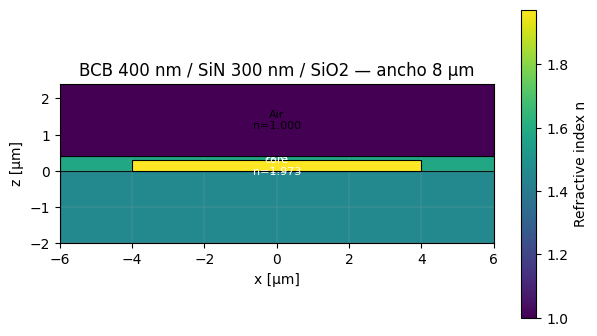

In [4]:
fig, ax = plot_cross_section(
    cross_section,
    wavelength_um=WAVELENGTH_UM,
    show_names=True,
    show_indices=True,
)
ax.set_title("BCB 400 nm / SiN 300 nm / SiO2 — ancho 8 µm")
plt.show()

## Resolución modal y cálculo de Lpi_TE

Se seleccionan los dos primeros modos clasificados como TE y se calcula $L_{\pi,\mathrm{TE}} = \pi / |\beta_{\mathrm{TE0}} - \beta_{\mathrm{TE1}}|$.

In [ ]:
solver = FemwellModeSolver(
    resolution_overrides={
        "core": {"resolution": 0.03, "distance": 0.25},
        "BCB": {"resolution": 0.04, "distance": 0.30},
        "Air": {"resolution": 0.25, "distance": 1.0},
        "background": {"resolution": 0.30, "distance": 1.0},
    },
    reference_material=THERMAL_SILICON_DIOXIDE,
    filter_guided=True,
    guided_tolerance=1e-2,
)

print("Resolviendo los modos necesarios con FEMWELL...", flush=True)
result = solver.solve(
    cross_section,
    wavelength_um=WAVELENGTH_UM,
    num_modes=NUM_MODES,
)

In [ ]:
te_modes = result.te_modes
if len(te_modes) < 2:
    raise RuntimeError(
        f"Se encontraron {len(te_modes)} modos TE; se necesitan al menos dos para calcular Lpi_TE."
    )

te0, te1 = te_modes[:2]
beta_te0 = float(np.real(te0.beta))
beta_te1 = float(np.real(te1.beta))
delta_beta_te = abs(beta_te0 - beta_te1)
if delta_beta_te <= 0.0:
    raise RuntimeError("TE0 y TE1 tienen la misma constante de propagación.")

lpi_te_um = float(np.pi / delta_beta_te)

print(f"n_eff(TE0) = {te0.neff.real:.8f}")
print(f"n_eff(TE1) = {te1.neff.real:.8f}")
print(f"beta_TE0 = {beta_te0:.8f} rad/um")
print(f"beta_TE1 = {beta_te1:.8f} rad/um")
print(f"Lpi_TE = {lpi_te_um:.6f} um")